# Test results: the 2013 partition

This notebook reads the single pre-registered test run from the project's MLflow store (`mlruns/`,
experiment `test`). `permits evaluate test` scored every model of `evaluation.test` in `config.yaml`
once on the 1,320 retained 2013 rows: the majority label, the four LinearSVC settings refit on the
training rows at their best validation grid point, and the three stored CamemBERTav2 models. The
bootstrap run holds 2,000 dossier-clustered resamples (1,318 dossiers), 95% percentile intervals,
and the paired differences of the primary and secondary comparisons. Nothing here trains or scores a
model. A CamemBERT test run is read only when the main run it loaded is current
(`tracking.holdout_models`: the current fingerprint and learning rate).

In [1]:
import os
import warnings

from tqdm import TqdmWarning

warnings.simplefilter("ignore", TqdmWarning)  # tqdm.auto (via transformers) lacks ipywidgets
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # silent table downloads

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from geneva_permits import tracking
from geneva_permits.config import FIGURES_DIR, load_config
from geneva_permits.evaluate import CLASSES
from geneva_permits.figures import save_figure
from geneva_permits.preprocess import load_texts

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODEL_COLORS = {"camembert": "#2a78d6", "linearsvc": "#eb6834", "majority": "#8a8a8a"}
LABELS = {"macro_f1": "macro-F1", "accuracy": "accuracy"}
PLAN = load_config()["evaluation"]["test"]

test_experiment = tracking.runs(tracking.TEST)
scored = tracking.holdout_runs()
summary = tracking.holdout_overview()
intervals = tracking.bootstrap_table()
bootstrap = tracking.bootstrap_run()
print(
    f"{len(scored)} model runs at commit {bootstrap['tags.git_commit'][:7]}; bootstrap:",
    f"{bootstrap['params.samples']} resamples over {bootstrap['params.distinct_groups']} dossiers",
)

8 model runs at commit ac1ae60; bootstrap: 2000 resamples over 1318 dossiers


## 1. Scores per model

**Question:** How do the models score on the 2013 rows, and does the validation ranking hold?

**Method:** `tracking.holdout_overview` gives one row per model, variant and weighting: the majority
run, each LinearSVC refit, and the CamemBERT mean over its three seeds. Macro-F1 is the pre-
registered primary metric; accuracy and per-class F1 are reported beside it.

In [3]:
summary[["model", "variant", "weighting", "C_log2", "ngram_range", "seed", "macro_f1", "accuracy"]]

,model,variant,weighting,C_log2,ngram_range,seed,macro_f1,accuracy
0,majority,NaN,NaN,NaN,NaN,NaN,0.059,0.311
1,linearsvc,A,none,-1,1-2,NaN,0.611,0.661
2,linearsvc,A,medium,-3,1-2,NaN,0.619,0.660
3,linearsvc,B,none,-1,1-2,NaN,0.617,0.657
4,linearsvc,B,medium,-3,1-2,NaN,0.617,0.658
5,camembert,NaN,none,NaN,NaN,"13, 42, 73",0.672,0.692


**Finding:** On the 2013 test set (1,320 records), CamemBERT is again the best model. It reaches a macro-F1 of 0.672 (the average of its three runs) and 69.2% accuracy. The four LinearSVC settings all score between 0.611 and 0.619, at about 66% accuracy, and always predicting the most common category (REN) gives only 0.059 at 31.1%. So the overall ranking from validation holds: CamemBERT first, LinearSVC clearly behind, and the baseline far behind. What does not hold is the choice between the LinearSVC settings: lemmatized text with medium weighting, the best setting on validation, scores exactly the same on the test as the same variant without weighting (0.617), and slightly lower than raw text with medium weighting (0.619). On the test, the four LinearSVC settings are practically equal. Each LinearSVC model was retrained with the settings chosen on validation: single words and word pairs everywhere, C = 2⁻³ with medium weighting and C = 2⁻¹ without.

## 2. CamemBERT per seed

**Question:** How far apart are the three stored CamemBERT models on the test, and does the kept
epoch matter?

**Method:** `tracking.camembert_seeds` joins each test run with the stored main run it loaded: the
epoch kept by the best-validation rule, its validation macro-F1, and its test macro-F1 and accuracy.

In [4]:
tracking.camembert_seeds()

,seed,kept_epoch,validation_macro_f1,test_macro_f1,test_accuracy
0,13,5,0.714,0.683,0.695
1,42,3,0.695,0.680,0.701
2,73,1,0.701,0.654,0.680


**Finding:** The three CamemBERT models, trained the same way except for their random seed, give noticeably different test results: a macro-F1 of 0.683, 0.680 and 0.654 (accuracy 69.5%, 70.1% and 68.0%). The gap between the best and the worst run is 2.9 points, larger than on validation (1.9 points) and larger than any difference between the four LinearSVC settings. The seed-13 model, kept at epoch 5, is the best on both validation and test. The seed-73 model, kept after only its first epoch, was in the middle on validation (0.701) but is clearly the weakest on the test. It is tempting to blame the early epoch, but with only three runs we cannot tell whether that is the reason or just chance. What the three runs do show is that a single CamemBERT run could have scored anywhere between about 0.65 and 0.68 on the test, depending on its seed. That is why the reported CamemBERT score is the average of all three runs rather than the result of one.

## 3. Intervals

**Question:** How precise are the test scores, given 1,320 rows?

**Method:** The bootstrap run stores, per model and metric, the estimate on all rows and the 2.5th
and 97.5th percentiles over 2,000 resamples of whole dossiers. CamemBERT's value on each resample is
the mean over its three seeds.

In [5]:
is_pair = intervals["comparison"].isin(["primary", "secondary"])
is_headline = intervals.index.get_level_values("metric").isin(["macro_f1", "accuracy"])
models = intervals[~is_pair & is_headline]
models

comparison  estimate    low   high
model              metric                                     
majority           macro_f1                0.059  0.056  0.063
                   accuracy                0.311  0.286  0.336
linearsvc A medium macro_f1                0.619  0.582  0.653
                   accuracy                0.660  0.633  0.686
linearsvc A none   macro_f1                0.611  0.568  0.650
                   accuracy                0.661  0.636  0.688
linearsvc B medium macro_f1                0.617  0.578  0.652
                   accuracy                0.658  0.633  0.685
linearsvc B none   macro_f1                0.617  0.573  0.657
                   accuracy                0.657  0.631  0.684
camembert          macro_f1                0.672  0.634  0.707
                   accuracy                0.692  0.668  0.716

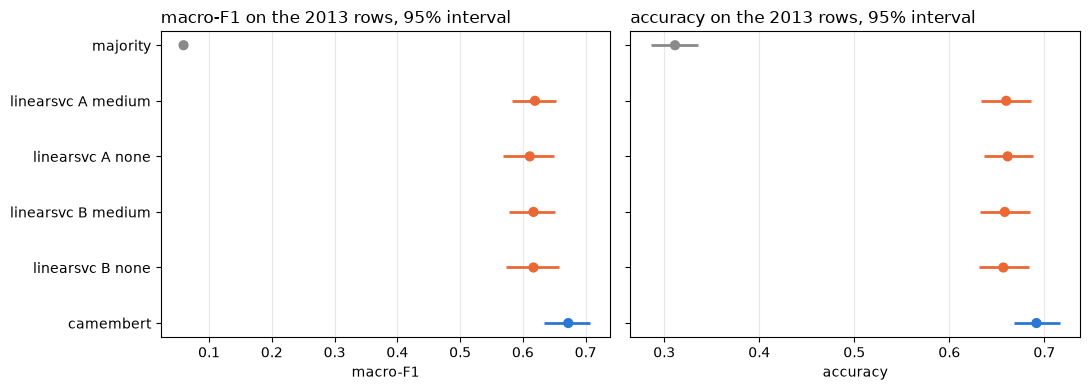

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metric in zip(axes, ["macro_f1", "accuracy"], strict=True):
    rows = models.xs(metric, level="metric")
    y = range(len(rows))
    colors = [MODEL_COLORS[name.split()[0]] for name in rows.index]
    ax.hlines(y, rows["low"], rows["high"], color=colors, linewidth=2)
    ax.scatter(rows["estimate"], y, color=colors, s=40, zorder=3)
    ax.set(yticks=list(y), yticklabels=rows.index, xlabel=LABELS[metric])
    ax.set_title(f"{LABELS[metric]} on the 2013 rows, 95% interval", loc="left")
    ax.grid(axis="x", alpha=0.3)
axes[0].invert_yaxis()
fig.tight_layout()
save_figure(fig, "test_intervals");

**Finding:** The 95% intervals show how much each test score could move if the test set had contained a different sample of similar records. For every trained model the interval is about 7 points wide in macro-F1 (CamemBERT 0.634–0.707, LinearSVC on lemmatized text with medium weighting 0.578–0.652) and about 5 points in accuracy. The intervals are this wide because the test set is small: 1,320 records, only 12 of them AFF. The four LinearSVC intervals overlap almost completely, and CamemBERT's interval also overlaps with theirs. Overlapping intervals do not mean the models are equally good, though: each interval also contains the ups and downs that both models share on the same records. The paired comparison in the next section removes that shared part and gives the clearer answer. Resampling whole dossiers instead of single records makes almost no difference here, because nearly every test record comes from its own dossier (only two of the 1,318 dossiers contain two records).

## 4. Comparisons

**Question:** Is CamemBERT's lead over the best LinearSVC real on the test, and do preprocessing or
weighting make a measurable difference?

**Method:** Paired differences from the same resamples: the primary comparison CamemBERT minus
LinearSVC B medium, and the two secondary ones, B medium minus A medium (lemmas against text) and B
medium minus B none (weighting). An interval that excludes zero marks a difference larger than the
resampling noise.

In [7]:
intervals[is_pair & is_headline]

comparison   estimate    low  \
model                                   metric                                  
camembert - linearsvc B medium          macro_f1    primary  5.542e-02  0.026   
                                        accuracy    primary  3.333e-02  0.018   
linearsvc B medium - linearsvc A medium macro_f1  secondary -2.377e-03 -0.024   
                                        accuracy  secondary -1.515e-03 -0.016   
linearsvc B medium - linearsvc B none   macro_f1  secondary -5.296e-06 -0.024   
                                        accuracy  secondary  1.515e-03 -0.012   

                                                   high  
model                                   metric           
camembert - linearsvc B medium          macro_f1  0.083  
                                        accuracy  0.050  
linearsvc B medium - linearsvc A medium macro_f1  0.019  
                                        accuracy  0.011  
linearsvc B medium - linearsvc B none   macro_f1  0.026  
                                        accuracy  0.015

**Finding:** CamemBERT is really better than the best LinearSVC, not just by chance. Comparing the two models on the same 2,000 resampled test sets, CamemBERT is ahead by 5.5 points of macro-F1, with a 95% interval from 2.6 to 8.3 points, and by 3.3 points of accuracy (interval 1.8 to 5.0). Neither interval includes zero, so in practically every resample CamemBERT comes out ahead. This interval is much narrower than the separate intervals of the two models, because the ups and downs both models share on the same records cancel out when they are compared directly. The two secondary comparisons show no real difference. Lemmatization changes LinearSVC's macro-F1 by −0.2 points (interval −2.4 to +1.9), and medium weighting compared with no weighting by 0.0 points (interval −2.4 to +2.6). Both intervals are centred on zero, so on the test neither the preprocessing nor the class weighting makes a measurable difference for LinearSVC. The small advantages they showed on validation did not hold.

## 5. Per-class scores

**Question:** Which classes drive the gap, and where do both models fail?

**Method:** Per-class F1 with its interval for CamemBERT (seed mean) and LinearSVC B medium from the
bootstrap table, then the paired per-class F1 difference CamemBERT − LinearSVC B medium from the
same stored table (the same resamples, nothing recomputed), then precision, recall and support
from the runs' per-class tables (CamemBERT averaged over the seeds with `tracking.mean_table`).

In [8]:
per_class = intervals.loc[["camembert", "linearsvc B medium"]].reset_index()
per_class = per_class[per_class["metric"].str.startswith("f1_")]
per_class["class"] = per_class["metric"].str[3:]
per_class = (
    per_class.pivot(index="class", columns="model", values=["estimate", "low", "high"])
    .swaplevel(axis=1)
    .sort_index(axis=1)
    .reindex(CLASSES)
)
per_class

model camembert               linearsvc B medium              
       estimate   high    low           estimate   high    low
class                                                         
AFF       0.372  0.557  0.167              0.264  0.426  0.098
AGR       0.554  0.651  0.436              0.522  0.637  0.384
AGV       0.696  0.787  0.593              0.568  0.682  0.439
EQU       0.701  0.756  0.642              0.696  0.756  0.634
NOU       0.771  0.842  0.685              0.688  0.774  0.587
PI        0.650  0.685  0.615              0.608  0.645  0.569
REN       0.698  0.730  0.666              0.688  0.721  0.654
VIL       0.936  0.968  0.898              0.902  0.947  0.852

In [9]:
pair = " - ".join(PLAN["primary_comparison"])
differences = intervals.loc[pair].loc[[f"f1_{c}" for c in CLASSES], ["estimate", "low", "high"]]
differences.index = CLASSES
differences["interval excludes 0"] = differences["low"].gt(0) | differences["high"].lt(0)
differences

,estimate,low,high,interval excludes 0
AFF,0.108,-0.048,0.257,False
AGR,0.032,-0.048,0.115,False
AGV,0.127,0.039,0.220,True
EQU,0.006,-0.038,0.051,False
NOU,0.084,0.024,0.145,True
PI,0.042,0.019,0.066,True
REN,0.011,-0.006,0.029,False
VIL,0.034,-0.004,0.075,False


In [10]:
names = test_experiment["tags.mlflow.runName"]
svc_run = test_experiment[names.eq("linearsvc-B-medium")].iloc[0]
tested = tracking.holdout_models()
bert_runs = tested[tested["params.model"].eq("camembert")]
pd.concat(
    {
        "LinearSVC B medium": tracking.table(svc_run["run_id"], "per_class.json"),
        "CamemBERT (seed mean)": tracking.mean_table(bert_runs["run_id"], "per_class.json"),
    },
    axis=1,
)

LinearSVC B medium                       CamemBERT (seed mean)         \
               precision recall     f1 support             precision recall   
class                                                                         
AFF                0.171  0.583  0.264      12                 0.281  0.556   
AGR                0.511  0.533  0.522      45                 0.508  0.615   
AGV                0.600  0.540  0.568      50                 0.652  0.747   
EQU                0.671  0.722  0.696     133                 0.679  0.727   
NOU                0.629  0.759  0.688      58                 0.778  0.764   
PI                 0.801  0.490  0.608     525                 0.825  0.536   
REN                0.594  0.818  0.688     411                 0.609  0.819   
VIL                0.897  0.907  0.902      86                 0.915  0.957   

                      
          f1 support  
class                 
AFF    0.372    12.0  
AGR    0.554    45.0  
AGV    0.696    50.0  
EQU    0.701   133.0  
NOU    0.771    58.0  
PI     0.650   525.0  
REN    0.698   411.0  
VIL    0.936    86.0

**Finding:** CamemBERT scores higher than LinearSVC on all eight categories. The biggest gains are on villa extensions (AGV, 0.696 vs 0.568), change of use (AFF, 0.372 vs 0.264) and new buildings (NOU, 0.771 vs 0.688); on the other five categories CamemBERT is ahead by 0.5 to 4 points. These per-category gaps were not tested directly, and the separate intervals of the two models overlap for every category, so they should be read as indications rather than proven differences. AFF remains the hardest category: with only 12 test records, its F1 could plausibly lie anywhere from 0.17 to 0.56 for CamemBERT and from 0.10 to 0.43 for LinearSVC. As on validation, the problem with AFF is false alarms, not missed cases: both models find more than half of the AFF records, but only 28% (CamemBERT) and 17% (LinearSVC) of their AFF predictions are correct. New villas (VIL) are the easiest category for both models (0.936 and 0.902). The two largest categories show the same pattern in both models. When a model predicts a minor construction (PI) it is usually right (precision about 0.80), but it finds only about half of the PI records (recall about 0.50), because many of them end up as renovations. Renovations (REN) show the reverse: the models find more than 80% of them, but only about 60% of their REN predictions are correct, because many of those are actually minor constructions.

## 6. Confusion matrices

**Question:** Which classes are confused with which on the test?

**Method:** True classes as rows, predicted as columns, on the 1,320 test rows. The CamemBERT matrix
is the mean over the three seeds, as in the validation notebook.

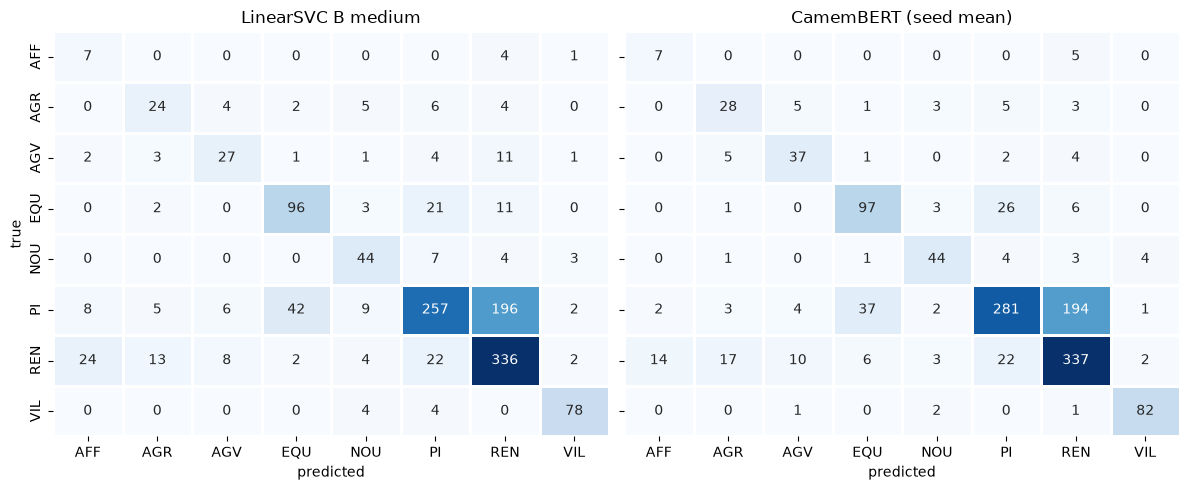

In [11]:
confusion = {
    "LinearSVC B medium": tracking.table(svc_run["run_id"], "confusion.json"),
    "CamemBERT (seed mean)": tracking.mean_table(bert_runs["run_id"], "confusion.json"),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (name, matrix) in zip(axes, confusion.items(), strict=True):
    sns.heatmap(matrix, annot=True, fmt=".0f", cmap="Blues", cbar=False, linewidths=1, ax=ax)
    ax.set(title=name, xlabel="predicted", ylabel="true" if ax is axes[0] else "")
fig.tight_layout()
save_figure(fig, "confusion_test");

**Finding:** One mistake dominates both confusion matrices: minor constructions (PI) predicted as renovations (REN). Both models do this for more than a third of the 525 PI records in the test set (196 for LinearSVC, 194 for CamemBERT on average), while the opposite mistake, renovations predicted as minor constructions, happens only 22 times for each model. The next most common mistakes are between minor constructions and public works (EQU), in both directions: 37 to 42 PI records predicted as EQU, and 21 to 26 EQU records predicted as PI. CamemBERT's advantage comes from the smaller categories. It correctly recognises 37 of the 50 villa extensions (AGV), against 27 for LinearSVC, and 28 of the 45 cases of added floor area (AGR), against 24. It also mistakes fewer renovations for a change of use (14 against 24), which is why its AFF predictions are more often correct. The confusion between minor constructions and renovations is a weakness both models share, not a difference between them. One possible contributing factor: the 2013 test set contains more minor constructions than renovations (525 against 411), while in the training years renovations were the most common category, so both models may have learned to lean towards REN.

## 7. Validation against test

**Question:** How much do the scores move from the 2011–2012 validation rows to the 2013 test rows?

**Method:** The validation overview of notebook 03 joined with the test summary on model, variant
and weighting; CamemBERT as the seed mean on both partitions.

In [12]:
validation = tracking.overview(tracking.runs(tracking.SELECTION))
keys = ["model", "variant", "weighting"]
shift = validation.merge(summary, on=keys, suffixes=("_validation", "_test"))
shift["macro_f1_shift"] = shift["macro_f1_test"] - shift["macro_f1_validation"]
shift[
    keys
    + [
        "macro_f1_validation",
        "macro_f1_test",
        "macro_f1_shift",
        "accuracy_validation",
        "accuracy_test",
    ]
]

,model,variant,weighting,macro_f1_validation,macro_f1_test,macro_f1_shift,accuracy_validation,accuracy_test
0,majority,NaN,NaN,0.073,0.059,-0.014,0.413,0.311
1,linearsvc,A,none,0.642,0.611,-0.031,0.729,0.661
2,linearsvc,A,medium,0.654,0.619,-0.035,0.725,0.660
3,linearsvc,B,none,0.657,0.617,-0.040,0.739,0.657
4,linearsvc,B,medium,0.661,0.617,-0.044,0.735,0.658
5,camembert,NaN,none,0.703,0.672,-0.031,0.760,0.692


**Finding:** Every model scores lower on the 2013 test than on the 2011–2012 validation set. CamemBERT drops by 3.1 points of macro-F1 (from 0.703 to 0.672), and the LinearSVC settings by 3.1 to 4.4 points. Accuracy drops even more, by 6.5 to 8.2 points, and the majority baseline falls from 41.3% to 31.1%. Because both kinds of model drop by about the same amount, the gap between them stays: CamemBERT is 4.2 points ahead on validation and 5.5 points ahead on the test. Two known reasons push the scores down. First, the validation scores were used to choose the settings, so they are slightly too optimistic by design. Second, the mix of categories changed: renovations (REN) make up 41% of the validation records but only 31% of the 2013 records, while minor constructions (PI), which the models often mistake for renovations, make up 40%. The majority baseline shows this shift most clearly, since it always predicts REN. With only one test year, we cannot tell how much of the drop comes from each reason.

## 8. Error analysis

**Question:** What do the models call the AFF rows, and what do the shared REN–PI and EQU–PI
confusions look like in the texts?

**Method:** `tracking.holdout_predictions` gives every model's prediction per test row, joined here
with the original descriptions. `seeds_agree` marks rows where the three CamemBERT seeds predict the
same class; the examples below are rows that LinearSVC B medium and all three seeds confused the
same way.

In [13]:
predictions = tracking.holdout_predictions()
texts = load_texts().set_index("record_key")["text"]
seeds = [f"camembert {seed}" for seed in PLAN["models"]["camembert"]["seeds"]]
svc = "linearsvc B medium"
rows = predictions.join(texts)
rows["seeds_agree"] = rows[seeds].nunique(axis=1).eq(1)
print(f"{len(rows)} test rows; the seeds agree on {rows['seeds_agree'].mean():.1%}")
aff = rows[rows["label"].eq("AFF")]
print(f"{len(aff)} AFF rows; predicted per model:")
display(pd.concat({m: aff[m].value_counts() for m in [svc, *seeds]}, axis=1).fillna(0).astype(int))
aff[["text", svc, *seeds]]

1320 test rows; the seeds agree on 84.7%
12 AFF rows; predicted per model:


,linearsvc B medium,camembert 13,camembert 42,camembert 73
AFF,7,8,7,5
REN,4,4,4,6
VIL,1,0,0,0
AGV,0,0,1,0
AGR,0,0,0,1


,text,linearsvc B medium,camembert 13,camembert 42,camembert 73
record_key,,,,,
APA 37877/1|2504924.75|1123257.98,changement d'affectation de logement en bureau au rez-de-chaussée,AFF,AFF,AFF,AFF
APA 38361/1|2500910.82|1116603.28,"changement d'affectation, transformation d'un cabinet dentaireen appartement et rénovation de celui-ci",AFF,AFF,AFF,REN
APA 38783/1|2500826.93|1117041.19,changement d'affectation de logement en bureau,AFF,AFF,AFF,AFF
APA 37654/1|2500902.71|1117415.49,changement d'affectation de locaux administratifs en logement au 4ème étage,AFF,AFF,AFF,AFF
APA 38091/1|2499301.45|1119110.88,transformation d'un appartement en bureauxau 1er étage,REN,AFF,AFF,REN
DD 106235/1|2502803.02|1119390.69,transformation de surfaces de bureaux en habitation individuelle (HPE 21.8%) - création d'une piscine et d'un garage...,VIL,REN,REN,REN
DD 106264/1|2498814.22|1121384.81,Modifications diverses du logement -,REN,REN,REN,REN
APA 37653/1|2500904.04|1117426.6,changement d'affectation de logement en locaux administratifs au 1er étage,AFF,AFF,AFF,AFF
DD 105719/1|2500200.37|1116409.61,agrandissement et transformation d'un garage en logement - installation de panneaux solaires,AFF,AFF,AGV,AGR


**Finding:** Most of the 12 change-of-use records (AFF) in the 2013 test say so explicitly, for example « changement d'affectation de logement en bureau » ("change of use from housing to office"). LinearSVC recognises 7 of them, and the three CamemBERT runs 8, 7 and 5. Almost every miss is labelled as a renovation (REN); only three misses go to other categories. The three CamemBERT runs give the same answer on 9 of the 12 records. Three records are missed by every model, and in all three the change of use is only implied, not stated: « aménagement d'une école » ("fitting out a school"), « modifications diverses du logement » ("various changes to the dwelling"), and offices converted into a house together with a pool and a garage, which LinearSVC labels as a new villa (VIL). In one more case, an explicit change of use of two rooms, LinearSVC is right while all three CamemBERT runs call it a renovation. Over the whole test set, the three CamemBERT runs agree on 84.7% of the records, so the choice of seed changes the answer for roughly one record in seven.

In [14]:
def shared_confusions(true, predicted, n=5):
    """Rows of class `true` that LinearSVC B medium and every CamemBERT seed called `predicted`."""
    shared = rows["label"].eq(true) & rows[svc].eq(predicted) & rows["seeds_agree"]
    shared &= rows[seeds[0]].eq(predicted)
    print(f"{true} called {predicted} by both models: {shared.sum()} rows")
    return rows.loc[shared, ["text"]].assign(true=true, predicted=predicted).head(n)


directions = [("REN", "PI"), ("PI", "REN"), ("EQU", "PI"), ("PI", "EQU")]
pd.concat([shared_confusions(true, predicted) for true, predicted in directions])

REN called PI by both models: 11 rows
PI called REN by both models: 163 rows
EQU called PI by both models: 11 rows
PI called EQU by both models: 18 rows


,text,true,predicted
record_key,,,
APAT 6110/1|2497877.35|1118871.06,construction d'une véranda et aménagements intérieurs,REN,PI
APAT 6128/1|2494614.08|1120255.41,construction d'une cheminée sur le toit,REN,PI
APA 39145/1|2497833.83|1126026.9,"ascenseur - adjonction d'un balcon, d'un couvert, de volets, deux tabatières - panneaux solaires thermiques - nouvel...",REN,PI
APA 38143/1|2502342.93|1118831.01,"bar et terrasse éphémère ""les Voiles By Genève Plage""",REN,PI
DD 106313/1|2497884.43|1120321.37,"ascenseur, véranda, escalier extérieur",REN,PI
APA 38962/1|2501285.94|1117018.69,remplacement des garde-corps,PI,REN
APA 38376/1|2500658.54|1117584.68,aménagement d'une boutique de vêtement,PI,REN
APA 38472/1|2497514.54|1114479.22,deux jours en toiture et transformations intérieures,PI,REN
APAT 6182/1|2497604.59|1115229.25,transformation et agrandissement des fenêtres existantes,PI,REN


**Finding:** Some mistakes are made by every model: LinearSVC and all three CamemBERT runs give the same wrong answer. By far the largest group of these shared mistakes is minor constructions (PI) labelled as renovations (REN), with 163 records; the other three kinds of shared mistake have only 11 to 18 records each. Reading the descriptions shows why. The minor constructions that get labelled as renovations describe work on an existing building, such as replacing railings, interior changes, enlarging windows, fire-safety upgrades or fitting out a shop, which sounds like renovation. The renovations that get labelled as minor constructions describe something added, such as a veranda, a chimney, a balcony with solar panels or a temporary bar, which sounds like a small new construction. The confusions between public works (EQU) and minor constructions involve small works outdoors, such as waste containers, parking spaces, a jetty, a skate ramp or an antenna, where the description does not say whether the land is public or private. So these are not cases where the models misread the text: the description simply does not contain the information the official category depends on.

## 9. Findings

- **CamemBERT is really better than LinearSVC on the 2013 test.** It reaches a macro-F1 of 0.672 against 0.617 for the LinearSVC setting chosen on validation (lemmatized text, medium weighting), and 69.2% against 65.8% accuracy. Compared on the same resampled test sets, CamemBERT is ahead by 5.5 points of macro-F1 (95% interval 2.6 to 8.3) and 3.3 points of accuracy (1.8 to 5.0). Neither interval includes zero, so the lead is not due to chance.

- **The LinearSVC settings are practically equal.** On the test, lemmatization and class weighting change macro-F1 by less than half a point, and their intervals are centred on zero. The small advantages these settings showed on validation did not hold.

- **The random seed matters for CamemBERT.** The three CamemBERT runs differ by 2.9 points on the test (0.654 to 0.683), more than on validation. A single run could therefore have given a misleadingly high or low score, which is why the reported result is the average of all three.

- **All models score lower on the test than on validation,** by 3 to 4 points of macro-F1 and 6.5 to 8 points of accuracy, but the gap between CamemBERT and LinearSVC stays. Two reasons push in the same direction: validation was used to choose the settings, which makes its scores slightly optimistic, and the 2013 records have a different mix of categories, with more minor constructions (40%) and fewer renovations (31%).

- **CamemBERT scores higher on all eight categories,** most clearly on villa extensions (AGV), change of use (AFF) and new buildings (NOU). These per-category gaps were not tested directly and the separate intervals overlap, so they are indications rather than proven differences. Change of use rests on only 12 test records: its F1 is 0.37 for CamemBERT and 0.26 for LinearSVC, with very wide intervals. For both models the problem is false alarms, not missed cases.

- **The biggest mistakes are shared and come from the categories themselves.** Both models label about 195 minor constructions as renovations, and they mix up minor constructions and public works in both directions. The descriptions behind these mistakes talk about work on existing buildings, small additions, or small outdoor works whose public or private status is not stated, so the text alone often cannot tell the categories apart.

- **Limitations.** There was one test run, on 1,320 records from a single year, with only 12 change-of-use records. Grouping the bootstrap by dossier made almost no difference here, because nearly every test record comes from its own dossier. The records from 2014–2026 were not used and remain reserved for the research extension.